# Federated Learning

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

ROOT = Path.home() / "Desktop/Project_lab"

baseline = pd.concat([
    pd.read_csv(f)
    for f in (ROOT / "results").glob("robot_*_training.csv")
    if "_federated_" not in f.name
], ignore_index=True)

federated = pd.concat([
    pd.read_csv(f)
    for f in (ROOT / "results").glob("*_federated_training.csv")
], ignore_index=True)

baseline["method"] = "Independent DDQN"
federated["method"] = "Federated DDQN"

benchmark = pd.concat(
    [baseline, federated],
    ignore_index=True
)

# Comparaison à budget identique
budget = benchmark.groupby(
    ["method", "robot"]
).size().min()

benchmark = (
    benchmark.sort_values("step")
    .groupby(["method", "robot"])
    .head(budget)
    .copy()
)

benchmark["interaction"] = (
    benchmark.groupby(["method", "robot"]).cumcount()
)

print("Budget par agent :", budget)

Budget par agent : 30298


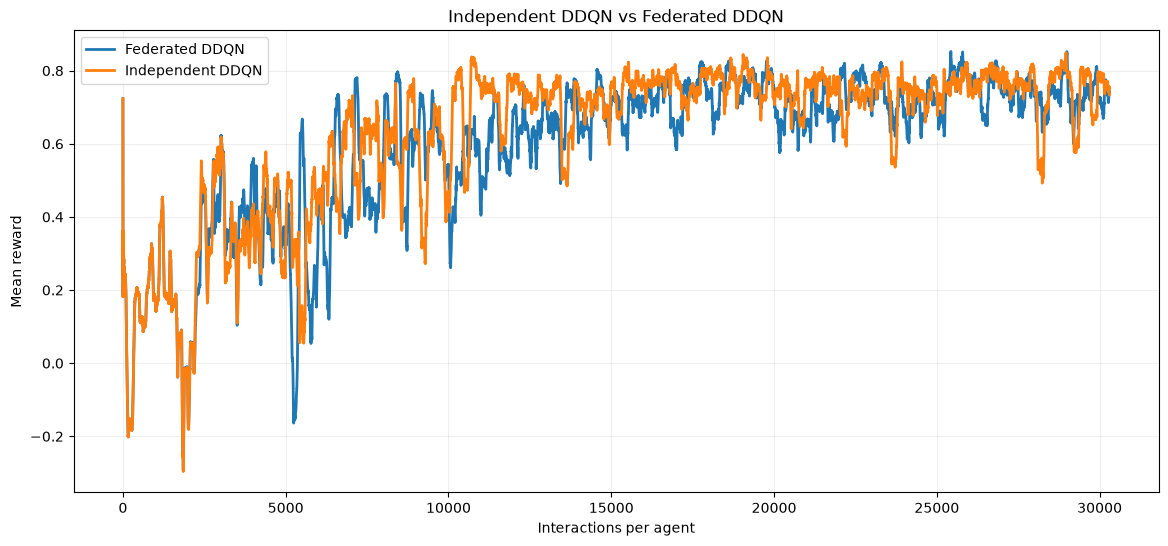

In [2]:
plt.figure(figsize=(14, 6))

for method, data in benchmark.groupby("method"):

    curve = (
        data.groupby("interaction")["reward"]
        .mean()
        .rolling(200, min_periods=1)
        .mean()
    )

    plt.plot(
        curve.index,
        curve.values,
        label=method,
        linewidth=2
    )

plt.title("Independent DDQN vs Federated DDQN")
plt.xlabel("Interactions per agent")
plt.ylabel("Mean reward")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [3]:
benchmark["stuck"] = benchmark["reason"].eq("stuck")

summary = benchmark.groupby("method").agg(
    transitions=("step", "count"),
    mean_reward=("reward", "mean"),
    std_reward=("reward", "std"),
    mean_distance=("min_distance", "mean"),
    stuck_resets=("stuck", "sum")
)

summary["stuck_per_1000"] = (
    summary["stuck_resets"]
    / summary["transitions"] * 1000
)

display(summary.round(4))

,transitions,mean_reward,std_reward,mean_distance,stuck_resets,stuck_per_1000
method,,,,,,
Federated DDQN,90894,0.5962,0.8016,0.5259,83,0.9132
Independent DDQN,90894,0.6287,0.7578,0.5274,70,0.7701
